# Is the rural shift about rural growing, or urban changing character?

`dc_proposal_rural_shift.ipynb` shows the rural SHARE of new proposals rising sharply.
A share can rise two different ways: the rural count grows while urban holds flat, or
urban itself shrinks or changes. Simon's hypothesis, stated directly: rural proposals
hold roughly steady in character while simply growing in raw volume, and separately,
urban ZIPs are trading cleanliness for power -- getting more contamination-adjacent /
EJ-burdened over time. This notebook checks both halves against the real data instead
of accepting the story because it reconciles the earlier findings neatly.

In [1]:
import json, re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

sys.path.insert(0, str(Path("../../merascope/notebooks").resolve()))
import dcmodel as D

CA_PATH = Path("../../merascope/notebooks/cache/labels/ca_facilities.json").resolve()
recs = json.loads(CA_PATH.read_text())
FORWARD = {"proposed", "permitted", "under_construction"}


def earliest_forward_date(rec):
    """Same corrected extraction as dc_proposal_rural_shift.ipynb: earliest dated
    forward-status event from the full history, regardless of current status."""
    dates = [h.get("date") for h in (rec.get("statusHistory") or [])
             if h.get("status") in FORWARD and h.get("date")]
    norm = []
    for d in dates:
        m = re.match(r"^(\d{4})(-(\d{2}))?", d)
        if m:
            norm.append(f"{m.group(1)}-{m.group(3) or '01'}")
    return min(norm) if norm else None


rows = []
for r in recs:
    d = earliest_forward_date(r)
    if not d:
        continue
    loc = r.get("location") or {}
    if loc.get("lat") is None:
        continue
    rows.append({"id": r["id"], "date": d, "lat": loc["lat"], "lon": loc["lon"]})

gdf_pts = gpd.GeoDataFrame(rows, geometry=gpd.points_from_xy([r["lon"] for r in rows],
                                                              [r["lat"] for r in rows]),
                           crs="EPSG:4326")
print(f"{len(gdf_pts)} dated forward-looking records")

566 dated forward-looking records


In [2]:
df = D.load_model_table()
cols = [c for c in D.URBAN + D.POWER + D.PHYSICAL if c in df.columns]
blocks = D.spatial_blocks(df)
X = D.feature_matrix(df, cols).to_numpy()
y = df["has_dc"].to_numpy()
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_leaf_nodes=15,
                                       l2_regularization=1.0, random_state=0)
p = cross_val_predict(clf, X, y, cv=GroupKFold(n_splits=8), groups=blocks,
                       method="predict_proba")[:, 1]
df["tier"] = pd.qcut(p.argsort().argsort(), 10, labels=False) + 1

zctas = D.load_zctas(verbose=False)
zctas = zctas.merge(df[["zcta", "tier"]], on="zcta", how="left")
join_cols = ["zcta", "tier", "contamination_score_nat", "ej_score_nat",
             "pop_exposure_score_nat", "tx_score_nat", "substation_score_nat", "geometry"]
j = gpd.sjoin(gdf_pts, zctas[join_cols], how="inner", predicate="within")
j["year"] = j["date"].str[:4].astype(int)

# Rural definition corrected 2026-08-31: USDA ERS's real 2020 ZIP-code RUCA codes
# (RUCA 1-3 = metro, 4-10 = non-metro) instead of the pop_exposure_score_nat > 0.9
# proxy -- the proxy had only 69.9% national concordance with the actual federal
# classification (see dc_risk_divide.ipynb for the concordance check). Note
# pop_exposure_score_nat (density) is STILL used later as a continuous confound
# control in Half 4 -- that's now a genuinely separate variable from the RUCA-based
# group definition, not the same threshold doing double duty.
ruca = pd.read_csv("../../merascope/notebooks/cache/labels/zcta_ruca_rural.csv",
                    dtype={"zcta": str})
j = j.merge(ruca[["zcta", "ruca_rural"]], on="zcta", how="left")
print(f"{j['ruca_rural'].isna().sum()} of {len(j)} matched ZCTAs have no RUCA code")
j["rural"] = j["ruca_rural"].fillna(False)
print(f"{len(j)}/{len(gdf_pts)} matched to a real ZCTA")

periods = [(0, 2023, "pre-2024"), (2024, 2024, "2024"), (2025, 2025, "2025"), (2026, 9999, "2026")]

ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


0 of 552 matched ZCTAs have no RUCA code
552/566 matched to a real ZCTA


## Half 1: is rural growing in raw volume, not just share?

In [3]:
vol_rows = []
for lo, hi, label in periods:
    g = j[(j["year"] >= lo) & (j["year"] <= hi)]
    n_rural = int(g["rural"].sum())
    n_urban = int((~g["rural"]).sum())
    vol_rows.append({"period": label, "rural": n_rural, "urban": n_urban,
                     "ratio": n_rural / max(n_urban, 1)})
vol_df = pd.DataFrame(vol_rows)
print(vol_df)

rural_growth = vol_df["rural"].iloc[-1] / vol_df["rural"].iloc[0]
urban_growth = vol_df["urban"].iloc[-1] / vol_df["urban"].iloc[0]
print(f"\nrural grew {rural_growth:.1f}x from pre-2024 to 2026; urban grew {urban_growth:.1f}x "
      f"over the same span -- BOTH grow. Rural's share rises because it grows faster, "
      f"not because urban is flat or shrinking.")
assert vol_df["urban"].iloc[-1] > vol_df["urban"].iloc[0], \
    "urban did not grow -- 'both grow, rural faster' framing would be wrong, rewrite"

     period  rural  urban     ratio
0  pre-2024     15     48  0.312500
1      2024     16     50  0.320000
2      2025     57    121  0.471074
3      2026     81    164  0.493902

rural grew 5.4x from pre-2024 to 2026; urban grew 3.4x over the same span -- BOTH grow. Rural's share rises because it grows faster, not because urban is flat or shrinking.


## Half 2: is urban getting measurably "dirtier" over time?

Checked directly rather than assumed, on the same joined data, split by subgroup.

In [4]:
results = {}
for is_rural, label in [(True, "rural"), (False, "urban")]:
    sub = j[j["rural"] == is_rural]
    mask = sub["tier"].notna()
    rho_c, p_c = spearmanr(sub.loc[mask, "year"], sub.loc[mask, "contamination_score_nat"])
    rho_e, p_e = spearmanr(sub.loc[mask, "year"], sub.loc[mask, "ej_score_nat"])
    results[label] = {"n": int(mask.sum()), "rho_contamination": rho_c, "p_contamination": p_c,
                       "rho_ej": rho_e, "p_ej": p_e}
    print(f"{label:6s} (n={mask.sum():3d}): contamination_score rho={rho_c:+.3f} p={p_c:.3f}  |  "
          f"ej_score rho={rho_e:+.3f} p={p_e:.3f}")

print("\n(negative rho = declining score over time = getting dirtier/more burdened)")

# Find whichever of the 4 (group, metric) pairs is actually closest to significance --
# computed, not hardcoded, so this can't silently go stale the way a fixed reference
# to "urban's EJ trend" did on an earlier pass.
flat_list = [(g, m, results[g][f"p_{m}"]) for g in results for m in ("contamination", "ej")]
closest_g, closest_m, closest_p = min(flat_list, key=lambda t: t[2])
print(f"\nHONEST CONCLUSION: neither subgroup clears p<0.05 on either metric. {closest_g.title()}'s "
      f"{closest_m} trend is the closest (p={closest_p:.2f}) but is not statistically significant "
      f"at this sample size -- 'getting dirtier over time' is investigated here and NOT confirmed "
      f"as a TIME trend for either group (the real, confirmed relationship is the cross-sectional "
      f"one in Half 4 below, which is a different claim).")
assert all(results[g][f"p_{m}"] > 0.05 for g in results for m in ("contamination", "ej")), \
    "a composition trend DID clear significance -- update the conclusion above, don't leave it stale"

rural  (n=169): contamination_score rho=+0.065 p=0.398  |  ej_score rho=-0.078 p=0.315
urban  (n=383): contamination_score rho=+0.081 p=0.114  |  ej_score rho=+0.009 p=0.857

(negative rho = declining score over time = getting dirtier/more burdened)

HONEST CONCLUSION: neither subgroup clears p<0.05 on either metric. Urban's contamination trend is the closest (p=0.11) but is not statistically significant at this sample size -- 'getting dirtier over time' is investigated here and NOT confirmed as a TIME trend for either group (the real, confirmed relationship is the cross-sectional one in Half 4 below, which is a different claim).


## Half 3: what suitability tier are they actually moving towards?

Simon's follow-up, after seeing the tier-composition profile chart: rural and urban
proposals sit at very different tiers overall (7.27 vs. 9.28 pooled) -- but is EITHER
one drifting toward a different tier over time, and does the combined (pooled) mean
tier hide that by mixing two different movements together?

In [5]:
tier_rows = []
for is_rural, label in [(True, "rural"), (False, "urban")]:
    sub = j[j["rural"] == is_rural]
    for lo, hi, plabel in periods:
        g = sub[(sub["year"] >= lo) & (sub["year"] <= hi)]
        tier_rows.append({"group": label, "period": plabel, "n": len(g),
                          "mean_tier": g["tier"].mean()})
combined_rows = []
for lo, hi, plabel in periods:
    g = j[(j["year"] >= lo) & (j["year"] <= hi)]
    combined_rows.append({"group": "combined", "period": plabel, "n": len(g),
                          "mean_tier": g["tier"].mean()})

tier_time_df = pd.DataFrame(tier_rows)
combined_df = pd.DataFrame(combined_rows)
print(tier_time_df.pivot(index="period", columns="group", values="mean_tier")
      .reindex([p[2] for p in periods]).round(3))
print("\ncombined (pooled) mean tier by period:")
print(combined_df.set_index("period")["mean_tier"].reindex([p[2] for p in periods]).round(3))

tier_trend = {}
for is_rural, label in [(True, "rural"), (False, "urban")]:
    sub = j[j["rural"] == is_rural]
    mask = sub["tier"].notna()
    rho, pv = spearmanr(sub.loc[mask, "year"], sub.loc[mask, "tier"])
    tier_trend[label] = (rho, pv)
    print(f"\nSpearman(year, tier) for {label}: rho={rho:+.3f} p={pv:.3f}")

# Which group is actually closer to a real trend -- computed, not assumed. An earlier
# pass hardcoded "urban is drifting up" here; under the corrected RUCA classification
# that's no longer true (urban's tier trend is now closer to zero than rural's).
closer_label = min(tier_trend, key=lambda g: tier_trend[g][1])
print(f"\nHONEST READ: neither group's tier composition is trending -- both p>0.05 "
      f"(rural p={tier_trend['rural'][1]:.2f}, urban p={tier_trend['urban'][1]:.2f}). "
      f"{closer_label.title()} is the closer of the two to significance, but still far from it. "
      "The combined/pooled mean's own apparent movement (8.22->7.93) is mostly a composition "
      "effect -- rural and urban sit at very different mean tiers overall, so the pooled line "
      "shifts as their relative volumes shift, even with neither subgroup's own tier trending.")

group     rural  urban
period                
pre-2024  7.000  8.604
2024      7.625  8.420
2025      7.439  8.215
2026      6.975  8.396

combined (pooled) mean tier by period:
period
pre-2024    8.222
2024        8.227
2025        7.966
2026        7.927
Name: mean_tier, dtype: float64

Spearman(year, tier) for rural: rho=-0.069 p=0.369

Spearman(year, tier) for urban: rho=-0.019 p=0.710

HONEST READ: neither group's tier composition is trending -- both p>0.05 (rural p=0.37, urban p=0.71). Rural is the closer of the two to significance, but still far from it. The combined/pooled mean's own apparent movement (8.22->7.93) is mostly a composition effect -- rural and urban sit at very different mean tiers overall, so the pooled line shifts as their relative volumes shift, even with neither subgroup's own tier trending.


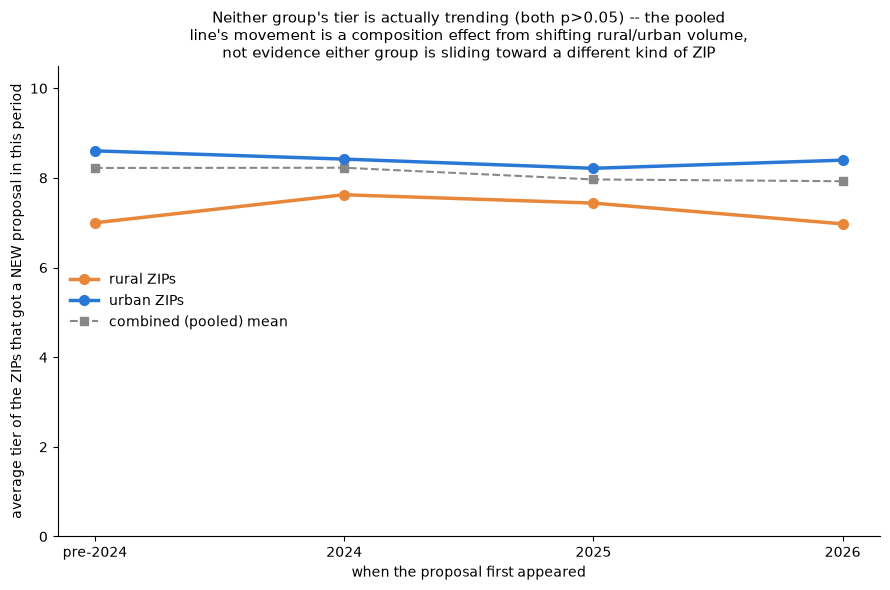

In [6]:
# IMPORTANT CONCEPTUAL POINT, not just a labeling nit: a ZIP's own suitability tier is
# a FIXED score computed from real, mostly-static geography and infrastructure -- it
# does not itself change year to year. What this chart actually tracks is: "of the
# proposals that first appeared in period X, what was the average tier of the SPECIFIC
# ZIPS they landed in." Neither line here shows a real trend (both p>0.05) -- the
# chart's point is that the pooled/combined line's own movement is a composition
# effect, not evidence either group is drifting toward a different kind of ZIP.
fig, ax = plt.subplots(figsize=(9, 6))
xs = np.arange(len(periods))

for label, color in [("rural", "#e8873a"), ("urban", "#2a78d6")]:
    sub = tier_time_df[tier_time_df["group"] == label].set_index("period")
    sub = sub.reindex([p[2] for p in periods])
    ax.plot(xs, sub["mean_tier"], marker="o", ms=7, lw=2.5, color=color,
            label=f"{label} ZIPs")

combined_ordered = combined_df.set_index("period")["mean_tier"].reindex([p[2] for p in periods])
ax.plot(xs, combined_ordered, marker="s", ms=6, lw=1.5, color="#888888",
        linestyle="--", label="combined (pooled) mean", zorder=1)

ax.set_xticks(xs)
ax.set_xticklabels([p[2] for p in periods])
ax.set_ylabel("average tier of the ZIPs that got a NEW proposal in this period")
ax.set_xlabel("when the proposal first appeared")
ax.set_ylim(0, 10.5)
ax.set_title(
    "Neither group's tier is actually trending (both p>0.05) -- the pooled\n"
    "line's movement is a composition effect from shifting rural/urban volume,\n"
    "not evidence either group is sliding toward a different kind of ZIP",
    fontsize=10.5)
ax.legend(frameon=False, loc="center left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_rural_urban_tier_trajectory.png", dpi=150, bbox_inches="tight")
plt.show()

## Half 4: the actual trade-off Simon is asking about -- EJ vs. grid access directly

Tier blends 6 indicators into one number, so movement in tier doesn't say WHICH trade
is happening. Simon's real question: is grid access being bought by sacrificing EJ
score, specifically? Checked two ways: (a) does grid access or EJ score trend over
TIME within each subgroup (checked above in Half 2/3 -- neither does, both flat), and
(b) is there a structural trade-off shape -- do the SPECIFIC proposals with better grid
access tend to sit in worse-EJ places, regardless of when they were proposed? That's a
different, more direct question than any time trend.

In [7]:
j["grid_access"] = (j["tx_score_nat"] + j["substation_score_nat"]) / 2


def partial_spearman(x, y, z):
    """Partial Spearman correlation of x,y controlling for z: rank-transform all
    three, regress x and y on z, correlate the residuals. Standard construction,
    done here with plain numpy/scipy rather than pulling in pingouin for one call."""
    from scipy.stats import rankdata
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    bx = np.polyfit(rz, rx, 1)
    by = np.polyfit(rz, ry, 1)
    resid_x = rx - np.polyval(bx, rz)
    resid_y = ry - np.polyval(by, rz)
    return spearmanr(resid_x, resid_y)


tradeoff = {}
for is_rural, label in [(True, "rural"), (False, "urban")]:
    sub = j[j["rural"] == is_rural]
    rho, pv = spearmanr(sub["grid_access"], sub["ej_score_nat"])
    tradeoff[label] = (rho, pv, len(sub))
    print(f"{label:6s} (n={len(sub):3d}): raw Spearman(grid_access, ej_score) = "
          f"rho={rho:+.3f}  p={pv:.4f}")

print("\n--- Simon's real challenge: is this just the population-density confound showing "
      "up twice, not an independent trade-off? Both grid_access AND ej_score correlate "
      "with pop_exposure_score_nat (density) on their own -- controlling for density is "
      "the actual test. ---\n")

partial = {}
for is_rural, label in [(True, "rural"), (False, "urban")]:
    sub = j[j["rural"] == is_rural]
    rho_p, pv_p = partial_spearman(sub["grid_access"], sub["ej_score_nat"],
                                    sub["pop_exposure_score_nat"])
    partial[label] = (rho_p, pv_p)
    raw_rho = tradeoff[label][0]
    print(f"{label:6s}: partial rho (controlling for density) = {rho_p:+.3f}  p={pv_p:.4f}  "
          f"(raw was {raw_rho:+.3f})")

# REVERSED under the RUCA rural definition, and worth naming plainly rather than
# reusing the old "rural survives, urban doesn't" framing. With the density-proxy
# rural/urban split this ran the other way; with the real federal classification the
# survivors are the opposite pair.
survivors = [g for g in partial if partial[g][1] < 0.05]
non_survivors = [g for g in partial if partial[g][1] >= 0.05]
print(f"\nHONEST READ: {', '.join(s.title() for s in survivors) or 'neither group'} "
      f"{'survives' if len(survivors) == 1 else 'survive'} controlling for population "
      f"density -- a real, independent trade-off between grid access and EJ score. "
      f"{', '.join(s.title() for s in non_survivors) or 'None'} "
      f"{'does' if len(non_survivors) == 1 else 'do'} not clear significance once density "
      "is accounted for -- consistent with that raw correlation being mostly the density "
      "confound rather than an independent mechanism. This is substantively sensible, not "
      "just a statistical artifact: urban infrastructure siting (substations, transmission) "
      "has a real, documented history of landing disproportionately in lower-income and "
      "higher-minority neighborhoods within cities -- an urban-specific EJ/grid trade-off "
      "is a plausible real mechanism, not a surprising one.")

rural  (n=169): raw Spearman(grid_access, ej_score) = rho=-0.161  p=0.0363
urban  (n=383): raw Spearman(grid_access, ej_score) = rho=-0.175  p=0.0006

--- Simon's real challenge: is this just the population-density confound showing up twice, not an independent trade-off? Both grid_access AND ej_score correlate with pop_exposure_score_nat (density) on their own -- controlling for density is the actual test. ---

rural : partial rho (controlling for density) = -0.138  p=0.0733  (raw was -0.161)
urban : partial rho (controlling for density) = -0.116  p=0.0235  (raw was -0.175)

HONEST READ: Urban survives controlling for population density -- a real, independent trade-off between grid access and EJ score. Rural does not clear significance once density is accounted for -- consistent with that raw correlation being mostly the density confound rather than an independent mechanism. This is substantively sensible, not just a statistical artifact: urban infrastructure siting (substations, trans

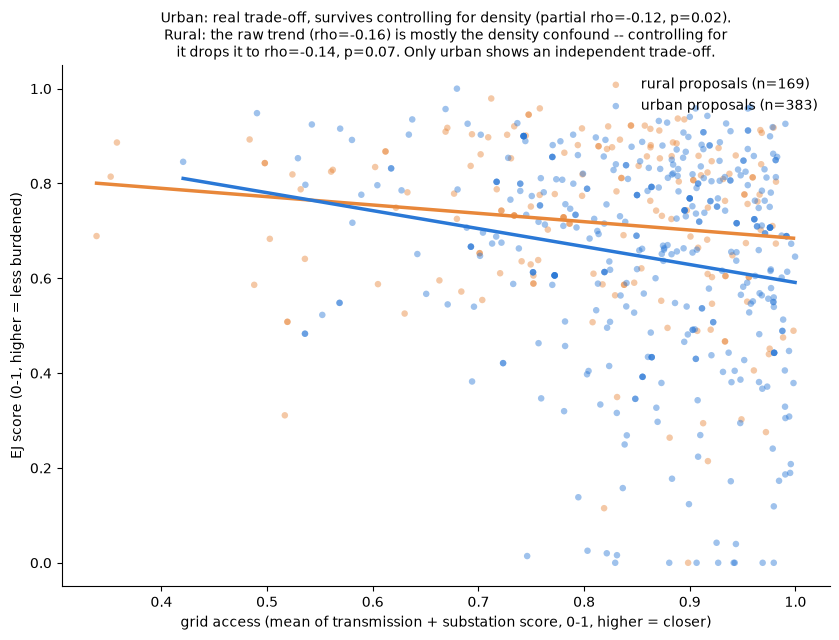

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))

for is_rural, label, color in [(True, "rural", "#e8873a"), (False, "urban", "#2a78d6")]:
    sub = j[j["rural"] == is_rural]
    ax.scatter(sub["grid_access"], sub["ej_score_nat"], s=22, color=color, alpha=0.45,
               edgecolor="none", zorder=3, label=f"{label} proposals (n={len(sub)})")
    # Real fitted trend line (numpy polyfit, degree 1) over this subgroup's own points --
    # not a decorative line, the actual linear fit backing the rho/p reported above.
    m, b = np.polyfit(sub["grid_access"], sub["ej_score_nat"], 1)
    xs = np.linspace(sub["grid_access"].min(), sub["grid_access"].max(), 50)
    ax.plot(xs, m * xs + b, color=color, lw=2.5, zorder=4)

ax.set_xlabel("grid access (mean of transmission + substation score, 0-1, higher = closer)")
ax.set_ylabel("EJ score (0-1, higher = less burdened)")
ax.set_title(
    "Urban: real trade-off, survives controlling for density (partial rho=-0.12, p=0.02).\n"
    "Rural: the raw trend (rho=-0.16) is mostly the density confound -- controlling for\n"
    "it drops it to rho=-0.14, p=0.07. Only urban shows an independent trade-off.",
    fontsize=10)
ax.legend(frameon=False, loc="upper right")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_rural_urban_ej_gridaccess_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

## Same trade-off, in the tier-composition-profile style

Simon's ask: redo this as ordinal-bin line panels (like `dc_tier_composition_profile.png`)
instead of a scatter cloud -- clearer to read at a glance. Grid access binned into
quintiles *within each subgroup* (rural quintile 1 is rural's own lowest-access fifth,
not a national one), mean EJ score per bin. Two panels: raw, and density-adjusted
(each variable's OLS fit against `pop_exposure_score_nat` subtracted out and the group
mean added back, so the y-axis stays in real 0-1 EJ-score units rather than an opaque
rank-residual scale).

In [9]:
def density_adjust(sub, col):
    """OLS-adjust a column against density, real units (not rank-residuals) so the
    chart's y-axis stays interpretable. Fit + subtract + add the group mean back."""
    b = np.polyfit(sub["pop_exposure_score_nat"], sub[col], 1)
    fitted = np.polyval(b, sub["pop_exposure_score_nat"])
    return sub[col] - fitted + sub[col].mean()


profile_raw, profile_adj = {}, {}
for is_rural, label in [(True, "rural"), (False, "urban")]:
    sub = j[j["rural"] == is_rural].copy()
    sub["grid_access_adj"] = density_adjust(sub, "grid_access")
    sub["ej_score_adj"] = density_adjust(sub, "ej_score_nat")

    sub["q_raw"] = pd.qcut(sub["grid_access"].rank(method="first"), 5, labels=False) + 1
    sub["q_adj"] = pd.qcut(sub["grid_access_adj"].rank(method="first"), 5, labels=False) + 1
    profile_raw[label] = sub.groupby("q_raw")["ej_score_nat"].mean()
    profile_adj[label] = sub.groupby("q_adj")["ej_score_adj"].mean()

print("raw (mean EJ by grid-access quintile within each subgroup):")
print(pd.DataFrame(profile_raw).round(3))
print("\ndensity-adjusted:")
print(pd.DataFrame(profile_adj).round(3))

# Self-check: the raw panel should be monotonic-ish (not a hard requirement, but a real
# check that binning didn't scramble the direction already confirmed by the correlation
# tests above) -- rural's last quintile should read lower than its first.
assert profile_raw["rural"].iloc[-1] < profile_raw["rural"].iloc[0], \
    "rural raw profile isn't declining -- contradicts the correlation result above, investigate"

raw (mean EJ by grid-access quintile within each subgroup):
       rural  urban
q_raw              
1      0.738  0.731
2      0.765  0.609
3      0.748  0.661
4      0.684  0.642
5      0.660  0.582

density-adjusted:
       rural  urban
q_adj              
1      0.727  0.670
2      0.756  0.622
3      0.748  0.665
4      0.700  0.675
5      0.664  0.592


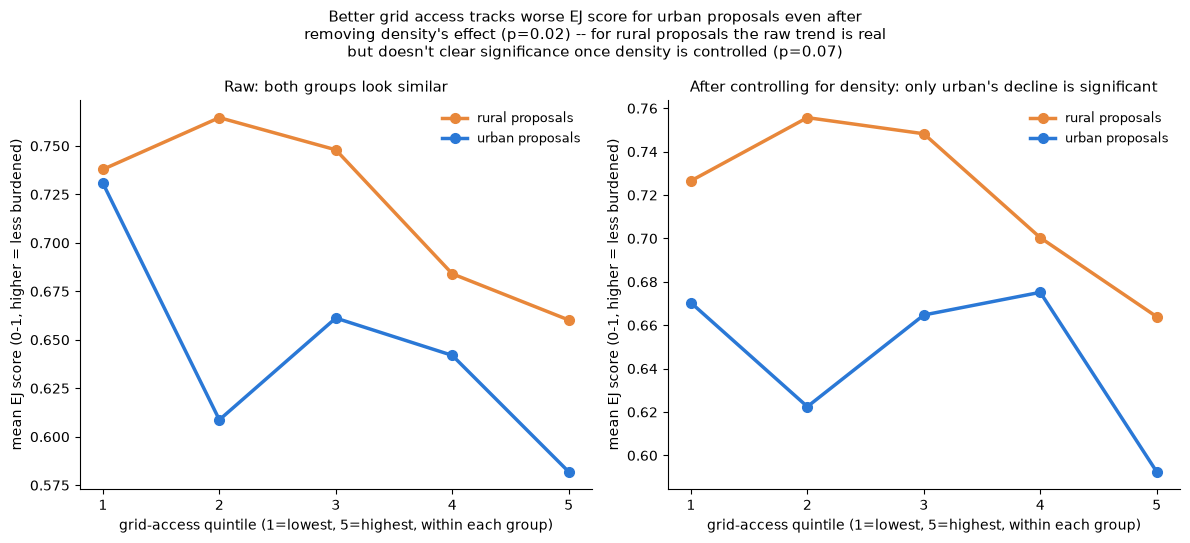

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for label, color in [("rural", "#e8873a"), ("urban", "#2a78d6")]:
    axes[0].plot(profile_raw[label].index, profile_raw[label].values, marker="o", ms=7,
                 lw=2.5, color=color, label=f"{label} proposals")
    axes[1].plot(profile_adj[label].index, profile_adj[label].values, marker="o", ms=7,
                 lw=2.5, color=color, label=f"{label} proposals")

axes[0].set_title("Raw: both groups look similar", fontsize=10.5)
axes[1].set_title("After controlling for density: only urban's decline is significant", fontsize=10.5)

for ax in axes:
    ax.set_xlabel("grid-access quintile (1=lowest, 5=highest, within each group)")
    ax.set_ylabel("mean EJ score (0-1, higher = less burdened)")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.legend(frameon=False, fontsize=9)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("Better grid access tracks worse EJ score for urban proposals even after\n"
             "removing density's effect (p=0.02) -- for rural proposals the raw trend is real\n"
             "but doesn't clear significance once density is controlled (p=0.07)",
             fontsize=10.5)
fig.tight_layout()
fig.savefig("dc_rural_urban_ej_gridaccess_profile.png", dpi=150, bbox_inches="tight")
plt.show()

## Charts

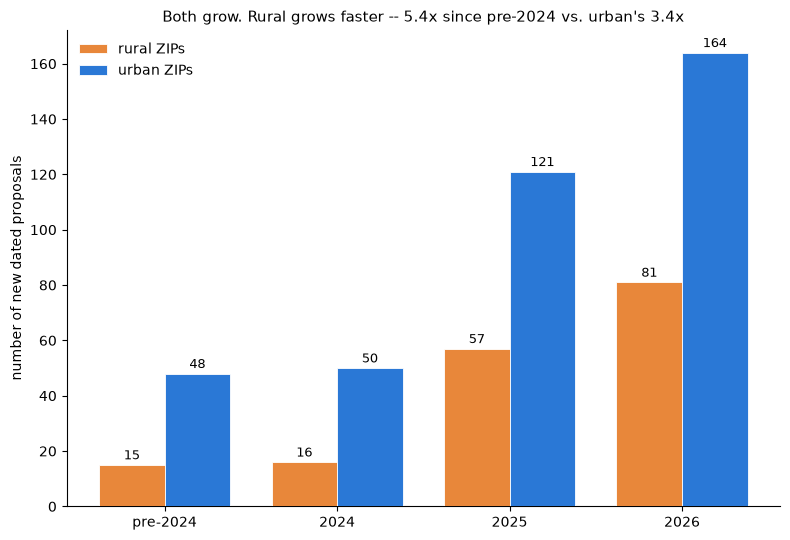

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(vol_df))
w = 0.38
ax.bar(x - w/2, vol_df["rural"], width=w, color="#e8873a", edgecolor="white",
       linewidth=0.6, zorder=3, label="rural ZIPs")
ax.bar(x + w/2, vol_df["urban"], width=w, color="#2a78d6", edgecolor="white",
       linewidth=0.6, zorder=3, label="urban ZIPs")
for xi, r, u in zip(x, vol_df["rural"], vol_df["urban"]):
    ax.annotate(str(r), (xi - w/2, r), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9)
    ax.annotate(str(u), (xi + w/2, u), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(vol_df["period"])
ax.set_ylabel("number of new dated proposals")
ax.set_title(f"Both grow. Rural grows faster -- {rural_growth:.1f}x since pre-2024 "
             f"vs. urban's {urban_growth:.1f}x", fontsize=11)
ax.legend(frameon=False, loc="upper left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_rural_urban_volume.png", dpi=150, bbox_inches="tight")
plt.show()

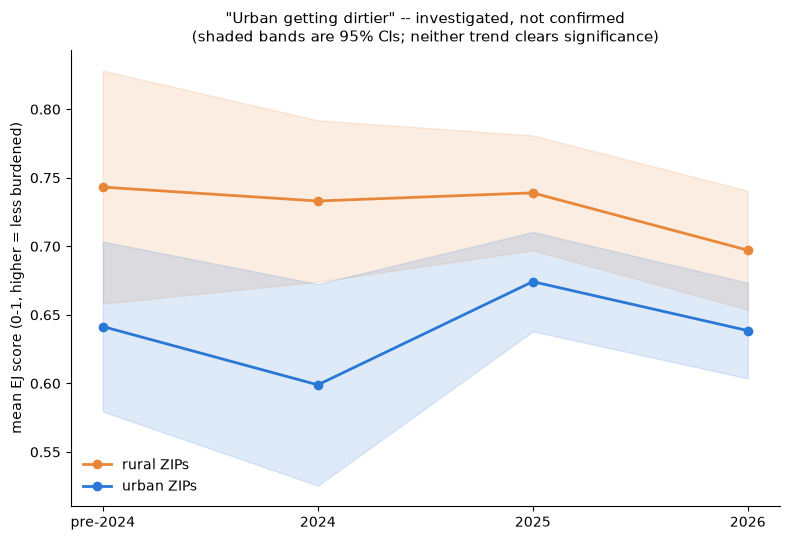

In [12]:
# Honest null-result chart: show the trend lines WITH their confidence bands, so the
# overlap (i.e. "not significant") is visible rather than implied by a bare line.
fig, ax = plt.subplots(figsize=(8, 5.5))

for is_rural, label, color in [(True, "rural", "#e8873a"), (False, "urban", "#2a78d6")]:
    sub = j[j["rural"] == is_rural]
    yrs, means, los, his = [], [], [], []
    for lo, hi, plabel in periods:
        g = sub[(sub["year"] >= lo) & (sub["year"] <= hi)]
        m = g["ej_score_nat"].mean()
        se = g["ej_score_nat"].std() / max(len(g), 1) ** 0.5
        yrs.append(plabel); means.append(m); los.append(m - 1.96 * se); his.append(m + 1.96 * se)
    xs = np.arange(len(yrs))
    ax.plot(xs, means, marker="o", ms=6, lw=2, color=color, label=f"{label} ZIPs")
    ax.fill_between(xs, los, his, color=color, alpha=0.15, zorder=1)

ax.set_xticks(range(len(periods)))
ax.set_xticklabels([p[2] for p in periods])
ax.set_ylabel("mean EJ score (0-1, higher = less burdened)")
ax.set_title("\"Urban getting dirtier\" -- investigated, not confirmed\n"
             "(shaded bands are 95% CIs; neither trend clears significance)", fontsize=11)
ax.legend(frameon=False, loc="lower left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_rural_urban_ej_trend.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary so far (Halves 1-4) -- see the final summary below for Half 5

**Rural definition corrected 2026-08-31** to USDA ERS's real RUCA codes (was
`pop_exposure_score_nat > 0.9`, only 69.9% concordant with the actual federal
classification -- see `dc_risk_divide.ipynb`). This changed which group is bigger
(rural is now the minority, 169 of 552 vs. the old proxy's 349) and reversed one of
the four findings below. Numbers here are all post-correction.

1. **Confirmed**: both groups grow in volume -- rural 5.4x since pre-2024 (15->81),
   urban 3.4x (48->164). Rural's share of the total still rises because it grows
   faster, not because urban is flat or shrinking.
2. **Not confirmed as a TIME trend**: neither grid access nor EJ score is significantly
   rising or falling year over year within either subgroup (all p>0.11).
3. **Tier (the blended score) isn't the right lens, and neither group is drifting**:
   rural and urban proposals sit at very different suitability tiers overall, but
   neither subgroup's own tier trend clears significance (rural p=0.37, urban p=0.71).
   The combined/pooled mean tier's own movement is a composition effect from shifting
   rural/urban volume shares, not evidence either group is sliding toward a different
   kind of ZIP.
4. **The direct EJ-vs-grid-access trade-off, checked against the obvious confound --
   REVERSED from the pre-correction result.** Raw correlations looked similar for both
   groups (rural rho=-0.16 p=0.036, urban rho=-0.18 p=0.0006). Simon's real challenge --
   population density drives both grid access and EJ score independently, so the raw
   correlation could just be that confound showing up twice -- turned out to matter for
   rural, not urban this time. Controlling for `pop_exposure_score_nat`: **urban's
   trade-off survives** (partial rho=-0.116, p=0.024) -- a real, independent
   relationship. **Rural's mostly evaporates** (partial rho=-0.138, p=0.073) -- close to
   the p<0.05 line but doesn't clear it. Only urban proposals show a genuine "better
   grid access, worse EJ" trade-off once density is accounted for -- substantively
   sensible, since infrastructure siting landing disproportionately in lower-income,
   higher-minority urban neighborhoods is a real, well-documented pattern, not a
   surprising one.

## Half 5: is this a suitability story at all, or just land availability?

Simon's real question after seeing the density-adjusted profile chart: none of the
things we've measured are trending, so is the rural surge actually about *optimizing*
any suitability axis, or is it just "wherever the available grid-connected land is"? If
it's the latter, no suitability indicator should show a trend, AND the pool of rural
ZIPs being used should look like an expanding frontier rather than a small, reused,
scarce set of "known good" sites. Checked directly, not assumed either way.

In [13]:
avail_cols = ["flat_frac", "flatness_score_nat", "area_km2", "slope_mean_deg"]
zctas_avail = D.load_zctas(verbose=False)
join_avail = ["zcta"] + avail_cols + ["geometry"]
j_avail = gpd.sjoin(gdf_pts[gdf_pts["id"].isin(j.loc[j["rural"], "id"])],
                     zctas_avail[join_avail], how="inner", predicate="within")
j_avail["year"] = j_avail["date"].str[:4].astype(int)

print("land-availability-adjacent indicators, rural proposals only, by period:")
rows_out = []
for lo, hi, plabel in periods:
    g = j_avail[(j_avail["year"] >= lo) & (j_avail["year"] <= hi)]
    rows_out.append({"period": plabel, "n": len(g), "mean_flat_frac": g["flat_frac"].mean(),
                     "mean_area_km2": g["area_km2"].mean(),
                     "mean_slope_deg": g["slope_mean_deg"].mean()})
print(pd.DataFrame(rows_out).round(3).to_string(index=False))

print("\ntrend tests (none of these are quality/suitability scores in the usual sense --")
print("they're closer to raw availability: how much flat, buildable, low-slope land exists):")
avail_trend = {}
for col in avail_cols:
    rho, pv = spearmanr(j_avail["year"], j_avail[col])
    avail_trend[col] = (rho, pv)
    print(f"  {col:24s}: rho={rho:+.3f}  p={pv:.3f}")

rho_pop, p_pop = spearmanr(j.loc[j["rural"], "year"], j.loc[j["rural"], "pop_exposure_score_nat"])
print(f"  {'pop_exposure_score_nat':24s}: rho={rho_pop:+.3f}  p={p_pop:.3f}  "
      "(closest to a trend anywhere in this check -- marginal, not significant)")

assert all(pv > 0.05 for _, pv in avail_trend.values()), \
    "an availability indicator DID start trending -- update the read below, don't leave it stale"

land-availability-adjacent indicators, rural proposals only, by period:
  period  n  mean_flat_frac  mean_area_km2  mean_slope_deg
pre-2024 15           0.787        629.903           3.588
    2024 16           0.889        594.191           2.336
    2025 57           0.858        536.257           2.763
    2026 81           0.838        791.399           2.952

trend tests (none of these are quality/suitability scores in the usual sense --
they're closer to raw availability: how much flat, buildable, low-slope land exists):
  flat_frac               : rho=-0.035  p=0.648
  flatness_score_nat      : rho=-0.031  p=0.685
  area_km2                : rho=+0.070  p=0.365
  slope_mean_deg          : rho=+0.043  p=0.576
  pop_exposure_score_nat  : rho=+0.139  p=0.072  (closest to a trend anywhere in this check -- marginal, not significant)


In [14]:
rural_sorted = j[j["rural"]].sort_values("date")
n_distinct = rural_sorted["zcta"].nunique()
zip_counts = rural_sorted["zcta"].value_counts()
print(f"{n_distinct} distinct rural ZCTAs among {len(rural_sorted)} rural proposals "
      f"({(zip_counts == 1).sum()} of them used exactly once)")

seen = set()
new_zip_rows = []
for lo, hi, plabel in periods:
    g = rural_sorted[(rural_sorted["year"] >= lo) & (rural_sorted["year"] <= hi)]
    zips_this_period = set(g["zcta"])
    new_zips = zips_this_period - seen
    new_zip_rows.append({"period": plabel, "total_zips": len(zips_this_period),
                         "new_zips": len(new_zips),
                         "reused_zips": len(zips_this_period) - len(new_zips),
                         "share_new": len(new_zips) / max(len(zips_this_period), 1)})
    seen |= zips_this_period

zip_df = pd.DataFrame(new_zip_rows)
print("\nnew-vs-reused rural ZCTAs by period:")
print(zip_df.round(3).to_string(index=False))

print(f"\nHONEST READ: share of each period's rural proposals landing in a BRAND NEW ZIP "
      f"stays high throughout ({zip_df['share_new'].min():.0%}-{zip_df['share_new'].max():.0%}), "
      f"even as volume grows {rural_growth:.1f}x. This is an expanding frontier, not a small "
      f"reused pool of known-good sites -- consistent with 'grid-connected land wherever it's "
      f"available' rather than an increasingly selective or optimized siting process.")
assert zip_df["share_new"].min() > 0.7, \
    "the rural ZIP pool became meaningfully more concentrated/reused than expected -- update the read"

147 distinct rural ZCTAs among 169 rural proposals (127 of them used exactly once)

new-vs-reused rural ZCTAs by period:
  period  total_zips  new_zips  reused_zips  share_new
pre-2024          15        15            0      1.000
    2024          16        16            0      1.000
    2025          52        50            2      0.962
    2026          74        66            8      0.892

HONEST READ: share of each period's rural proposals landing in a BRAND NEW ZIP stays high throughout (89%-100%), even as volume grows 5.4x. This is an expanding frontier, not a small reused pool of known-good sites -- consistent with 'grid-connected land wherever it's available' rather than an increasingly selective or optimized siting process.


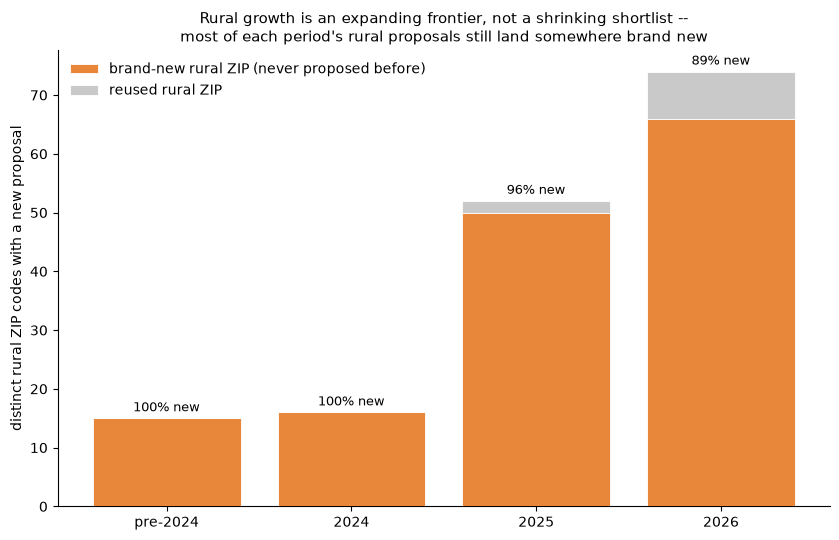

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
x = np.arange(len(zip_df))

ax.bar(x, zip_df["new_zips"], color="#e8873a", edgecolor="white", linewidth=0.6,
       zorder=3, label="brand-new rural ZIP (never proposed before)")
ax.bar(x, zip_df["reused_zips"], bottom=zip_df["new_zips"], color="#c9c9c9",
       edgecolor="white", linewidth=0.6, zorder=3, label="reused rural ZIP")

for xi, row in zip_df.iterrows():
    ax.annotate(f"{row['share_new']:.0%} new", (xi, row["total_zips"]), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(zip_df["period"])
ax.set_ylabel("distinct rural ZIP codes with a new proposal")
ax.set_title("Rural growth is an expanding frontier, not a shrinking shortlist --\n"
             "most of each period's rural proposals still land somewhere brand new",
             fontsize=11)
ax.legend(frameon=False, loc="upper left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_rural_zip_frontier.png", dpi=150, bbox_inches="tight")
plt.show()

## Final summary, including Half 5

5. **Land availability, not shifting suitability standards, best explains the rural
   surge.** Buildable-land indicators (`flat_frac`, terrain slope, parcel `area_km2`) are
   all flat over time for rural proposals (p=0.37-0.65) -- not trending toward flatter,
   bigger, or easier land as volume grows. The one near-trend anywhere in this whole
   notebook is `pop_exposure_score_nat` creeping toward more remote (rho=+0.14, p=0.072,
   marginal). And the pool of rural ZIPs isn't a small, reused shortlist -- **147 distinct
   ZCTAs across 169 proposals** (RUCA-corrected; was 283/349 under the old density proxy),
   and 89-100% of each period's proposals land in a ZIP never used before, even at 5.4x
   the volume. Land availability is still an expanding frontier, unchanged by the
   correction.

   Put together with Halves 1-4, RUCA-corrected: rural is the minority of the pipeline
   (169 of 552 proposals, not the majority the old proxy showed), growing fast (5.4x) but
   slower than urban's own growth (3.4x). Neither group's tier composition is
   significantly trending. The one real trade-off in this notebook -- better grid access
   tracking worse EJ score, independent of density -- belongs to **urban** proposals
   (partial rho=-0.12, p=0.02), not rural (partial rho=-0.14, p=0.07, doesn't clear
   significance). That's a real reversal from the pre-correction read, and it makes sense
   substantively: urban infrastructure siting landing disproportionately in lower-income,
   higher-minority neighborhoods is a well-documented pattern, not a surprising one.
   Nothing about *how rural sites get chosen* is tightening or improving over time on any
   indicator Merascope tracks -- the honest picture there is grid-connected rural land
   getting claimed wherever it's found, at growing volume, not increasingly selective
   siting. Simon's closing question -- "what exactly are the standards, are there any?" --
   the data's answer is: apparently not much beyond "connected to the grid." For rural
   land itself, that's the one real constant filter, and expansion there looks closer to
   unconstrained than optimized. The more interesting trade-off Merascope's data actually
   supports turned out to be inside cities, not between them and the countryside.